# QBO zonal wind

## Purpose

Evaluate the QBO zonal-wind evolution of the experiments against ERA-Interim and ERA5.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Monthly CMIP-named `ua` (`cmip_ts/monthly`, 19 pressure levels). References: ERA5 and ERA-Interim monthly pressure-level `ua` (E3SM Diags time series under `OBSERVATION_ROOT`; 0.25 and 0.75 degree, read lazily and subset to the model levels and 5S-5N before computing).

## Method

5S-5N cos-lat weighted zonal mean on the model levels (hPa). Amplitudes: half peak-to-peak, RMS, and detrended RMS over the record. Spectral amplitudes need >= 8 years and are not computed for 2012-2013. Scores: RMSE/PCC of the sections, averaged over both reanalyses and against `REFERENCE` alone, with a 95% moving-block bootstrap CI (`BLOCK_LEN`-month blocks).

## Outputs

`data/hind_atm_eval/qbo/qbo_<SOURCE>_ua_<period>.nc` (also read by notebook 02), `qbo_ua_skill_<REFS>.csv`; figures in `figure/hind_atm_eval/qbo/`:

1. Time-pressure sections of the reference and all sources, RMSE/PCC vs the reference annotated.
2. Source − reference differences.
3. RMS amplitude profiles.
4. RMSE/PCC skill bars, averaged over both reanalyses (their own disagreement drawn as a floor) and vs one reference.
5. Persistence of the initial vertical profile and correlation with the reference vs lead month.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
REFERENCES = ("ERAI", "ERA5")  # sections for both; skill averaged over them
REFERENCE = "ERAI"             # sections, differences and single-reference skill against this one
OTHER_REANALYSIS = "ERA5"      # also drawn as a source
LAT_BAND = (-5.0, 5.0)
BLOCK_LEN = 6                  # months per bootstrap block
N_BOOT = 500
FORCE_COMPUTE = False
FONT_SCALE = 14
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'qbo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step.

In [4]:
from configs.hind_experiment_config import PERIOD
from util.qbo_diagnostics import open_qbo_input, qbo_section_path

VARIABLE = "ua"
SOURCES = (*REFERENCES, *EXPERIMENTS)
paths = {s: qbo_section_path(data_dir, s, VARIABLE) for s in SOURCES}
inputs = {s: open_qbo_input(s, VARIABLE, data_root=INPUT_DATA_ROOT, **ROOTS)
          for s in SOURCES if FORCE_COMPUTE or not paths[s].exists()}
print(f"[READ] {', '.join(inputs) or 'nothing: every section is saved'}")

[READ] nothing: every section is saved


## 5. Derive

Equatorial time-height section and amplitude profiles per source. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.qbo_diagnostics import QboAnalyzer, QboConfig

analyzer = QboAnalyzer(QboConfig.for_variable(VARIABLE, lat_band=LAT_BAND))
reduced = compute_all({s: analyzer.reduce(da) for s, da in inputs.items()})
derived = {s: analyzer.compute_metrics(f"{s}_{VARIABLE}_{PERIOD}", da).assign_attrs(source=s)
           for s, da in reduced.items()}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files. Check: RMS amplitude at 30 hPa per source.

In [6]:
for s, ds in derived.items():
    ds.to_netcdf(paths[s])
    print(f"[WRITE] {paths[s]}")
sections = {s: xr.load_dataset(p) for s, p in paths.items()}
display(pd.Series({s: float(ds.amp_rms.sel(plev=30)) for s, ds in sections.items()},
                  name="amp_rms_30hPa").round(2))

ERAI      18.97
ERA5      19.06
CTRL      12.83
DARTOP    18.41
ERA5OP    17.71
ERA5DL    17.54
ERA5BL    19.43
DARTBL    18.07
DARTBA    14.96
DARTAE    19.20
Name: amp_rms_30hPa, dtype: float64

## 7. Scores

RMSE/PCC of every experiment, averaged over `REFERENCES` and against `REFERENCE`.

In [7]:
from util.qbo_plotting import QboPlotParameter, QboPlotter

plotter = QboPlotter(QboPlotParameter.for_variable(VARIABLE), data_dir)
skill = {}
for refs in (list(REFERENCES), [REFERENCE]):
    tag = "_".join(refs)
    skill[tag] = plotter.skill_table(refs, EXPERIMENTS, n_boot=N_BOOT, block_len=BLOCK_LEN)
    skill[tag].to_csv(data_dir / f"qbo_ua_skill_{tag}.csv", index=False)
    print(f"[WRITE] {data_dir / f'qbo_ua_skill_{tag}.csv'}")
    display(skill[tag].round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/qbo_ua_skill_ERAI_ERA5.csv


,source,rmse,pcc,rmse_lo,rmse_hi,pcc_lo,pcc_hi,rmse_ref_halfrange,pcc_ref_halfrange
0,CTRL,16.19,-0.33,15.77,16.64,-0.55,-0.18,0.14,0.02
1,DARTOP,12.71,0.30,10.80,14.42,-0.06,0.54,0.07,0.01
2,ERA5OP,14.48,0.15,12.90,16.13,-0.20,0.41,0.05,0.02
3,ERA5DL,14.88,0.14,13.29,16.57,-0.19,0.35,0.09,0.01
4,ERA5BL,14.10,0.27,12.01,16.07,-0.03,0.48,0.11,0.00
5,DARTBL,12.94,0.29,11.16,14.50,0.01,0.54,0.15,0.00
6,DARTBA,16.39,-0.34,15.93,17.04,-0.57,-0.19,0.11,0.03
7,DARTAE,13.83,0.24,11.91,15.46,-0.10,0.49,0.03,0.01


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/qbo_ua_skill_ERAI.csv


,source,rmse,pcc,rmse_lo,rmse_hi,pcc_lo,pcc_hi,rmse_ref_halfrange,pcc_ref_halfrange
0,CTRL,16.33,-0.31,15.92,16.72,-0.54,-0.14,0.0,0.0
1,DARTOP,12.78,0.31,10.82,14.36,-0.05,0.54,0.0,0.0
2,ERA5OP,14.52,0.17,12.99,16.05,-0.18,0.40,0.0,0.0
3,ERA5DL,14.97,0.15,13.39,16.48,-0.17,0.35,0.0,0.0
4,ERA5BL,14.21,0.27,12.07,16.02,-0.03,0.48,0.0,0.0
5,DARTBL,13.09,0.29,11.31,14.45,0.02,0.52,0.0,0.0
6,DARTBA,16.50,-0.32,15.92,17.08,-0.56,-0.14,0.0,0.0
7,DARTAE,13.87,0.26,11.98,15.38,-0.09,0.49,0.0,0.0


## 8. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_sections_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_diffs_vs_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_amplitude_rms.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_skillbars_ERAI_ERA5.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_skillbars_ERAI.png
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_persistence_vs_ERAI.png


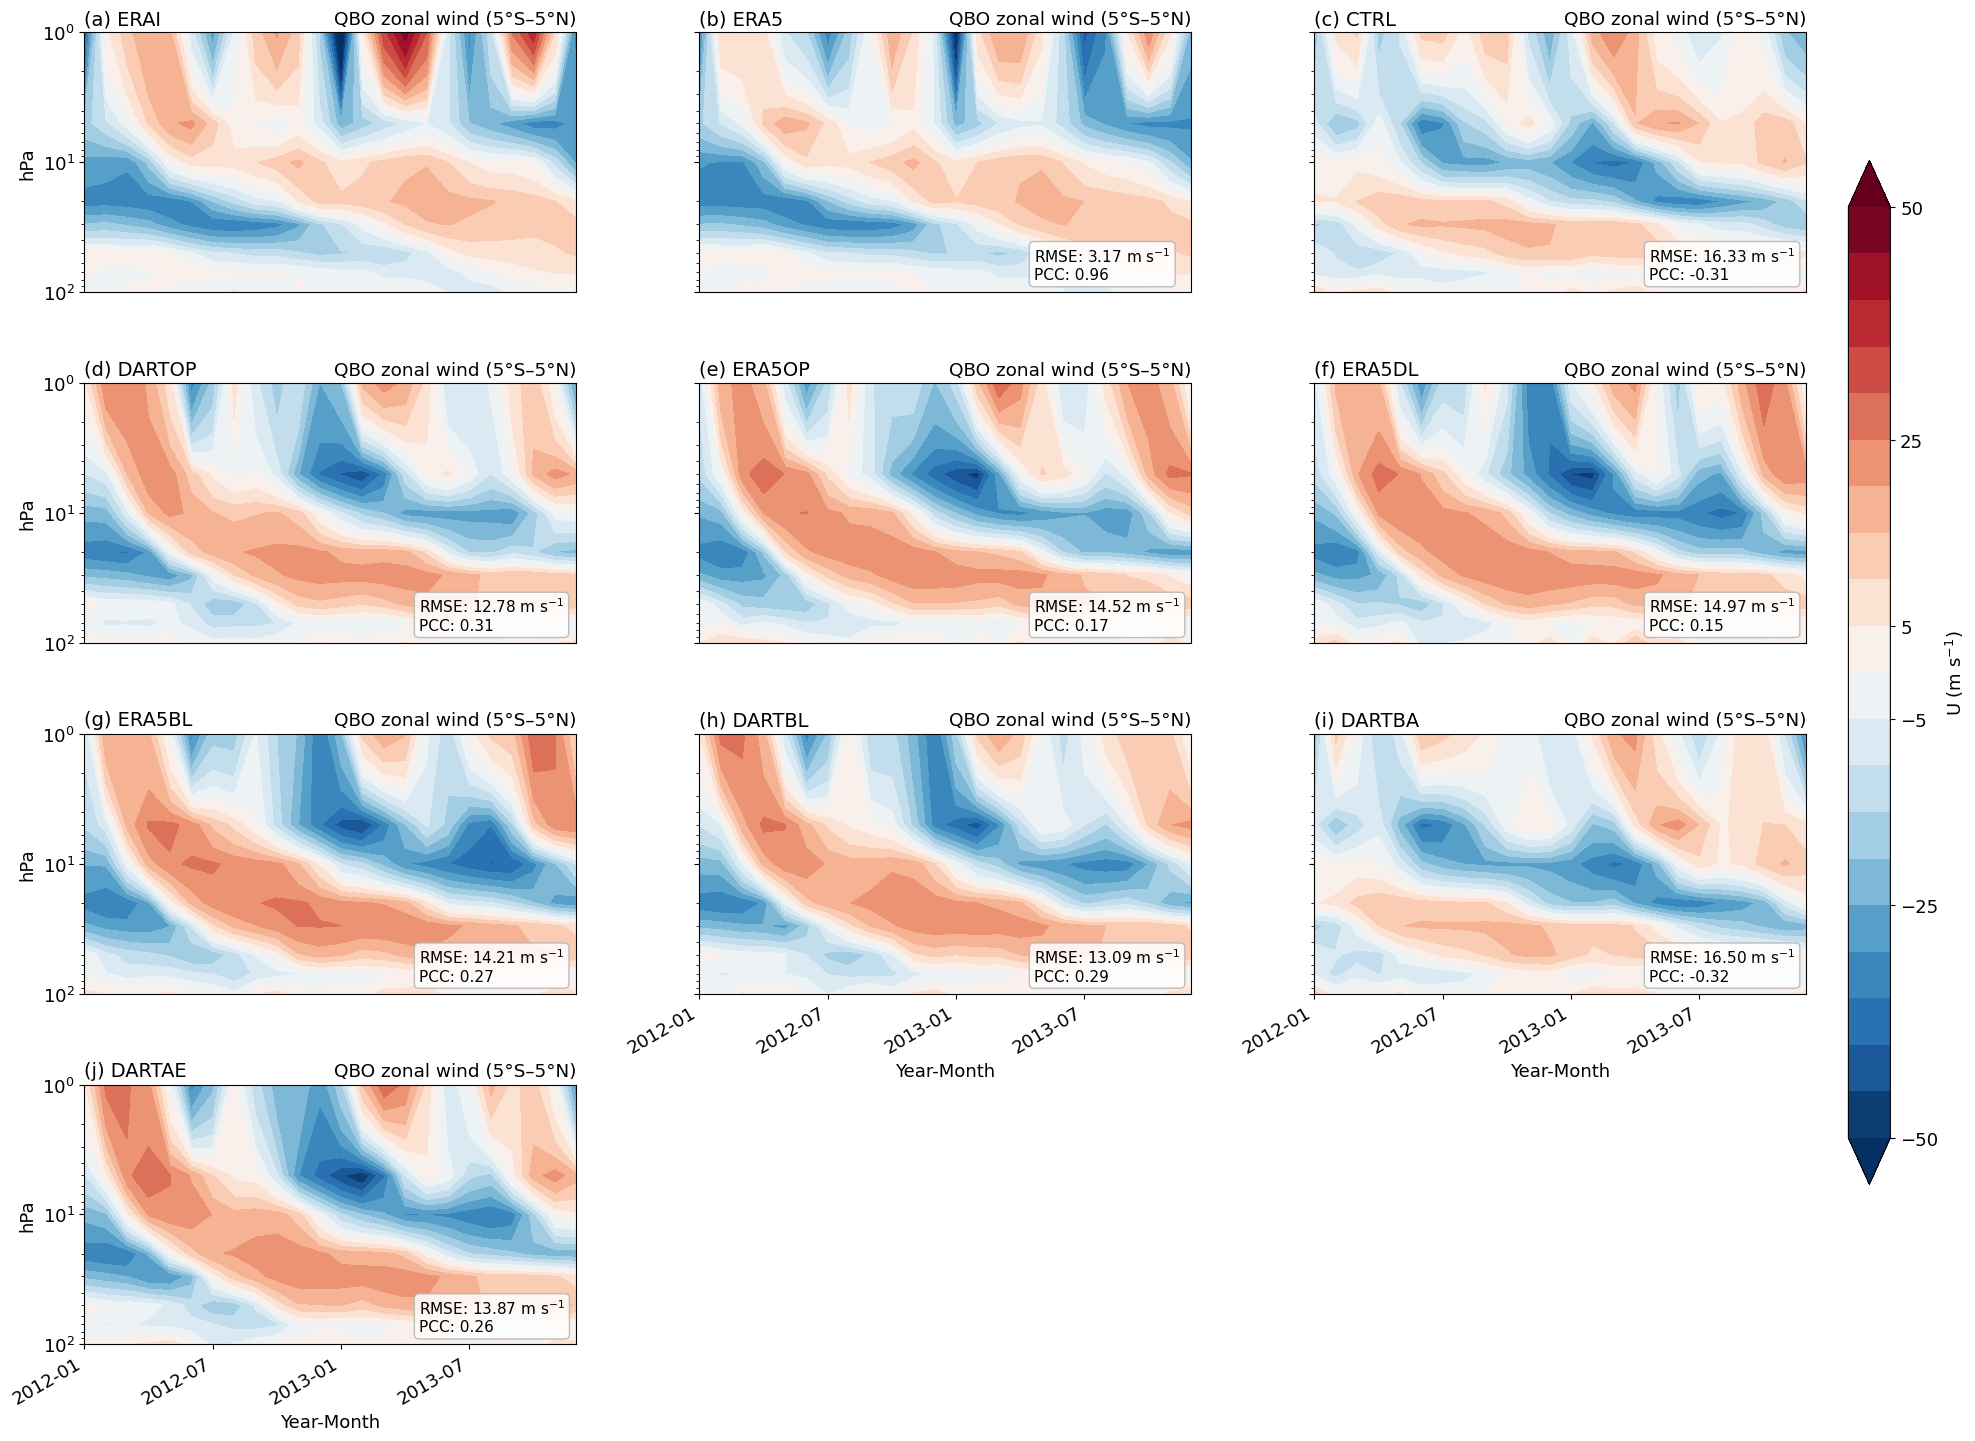

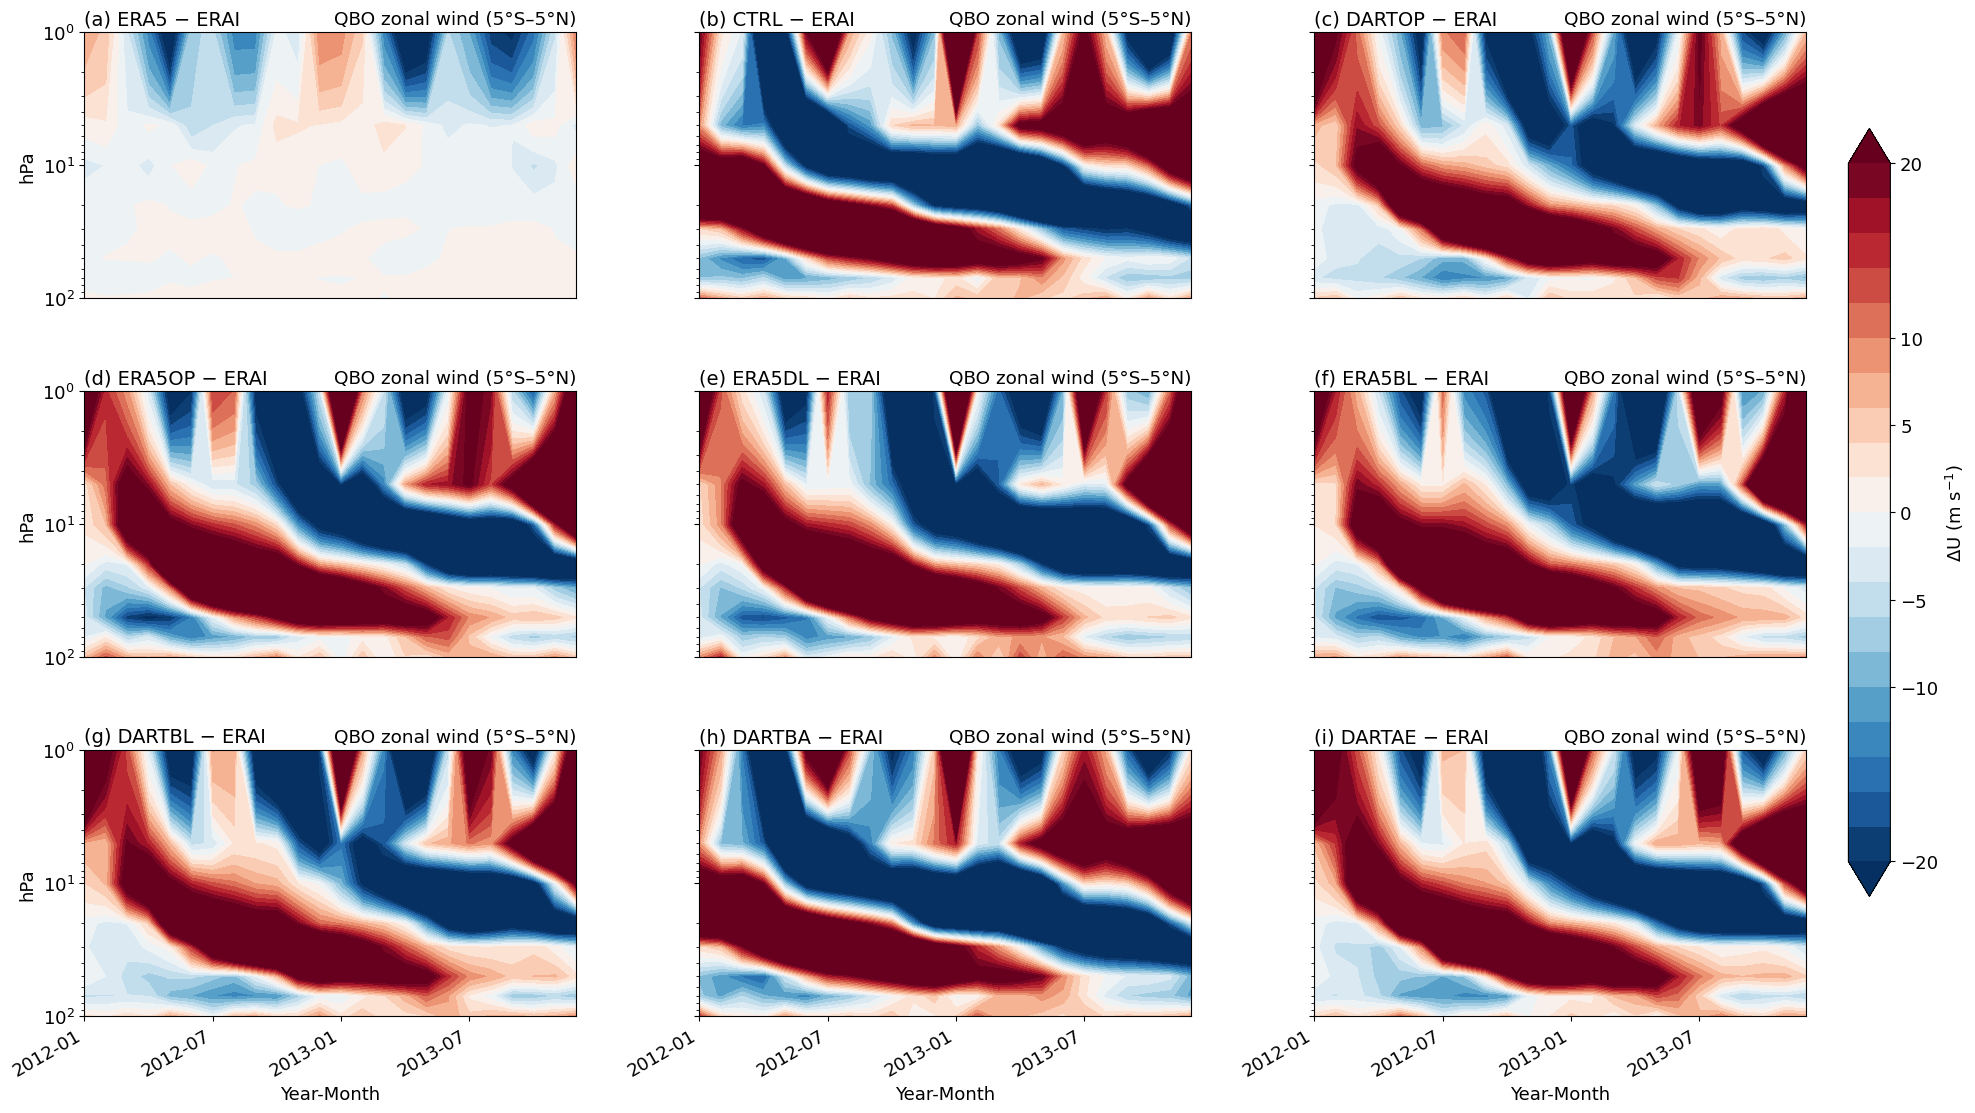

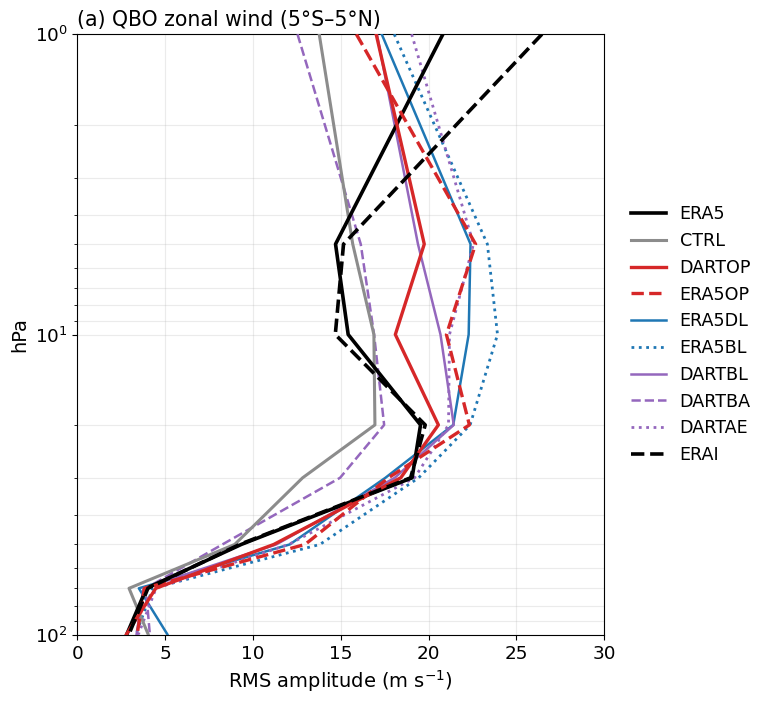

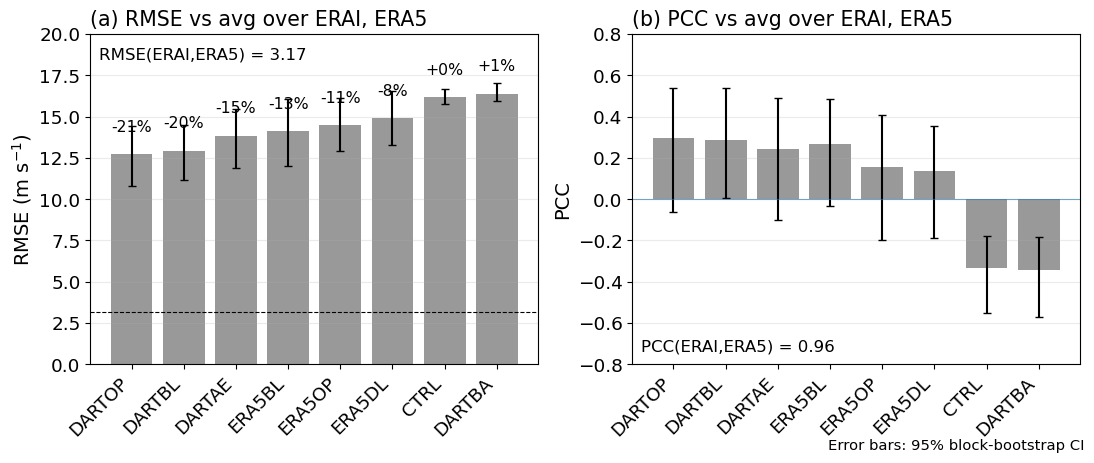

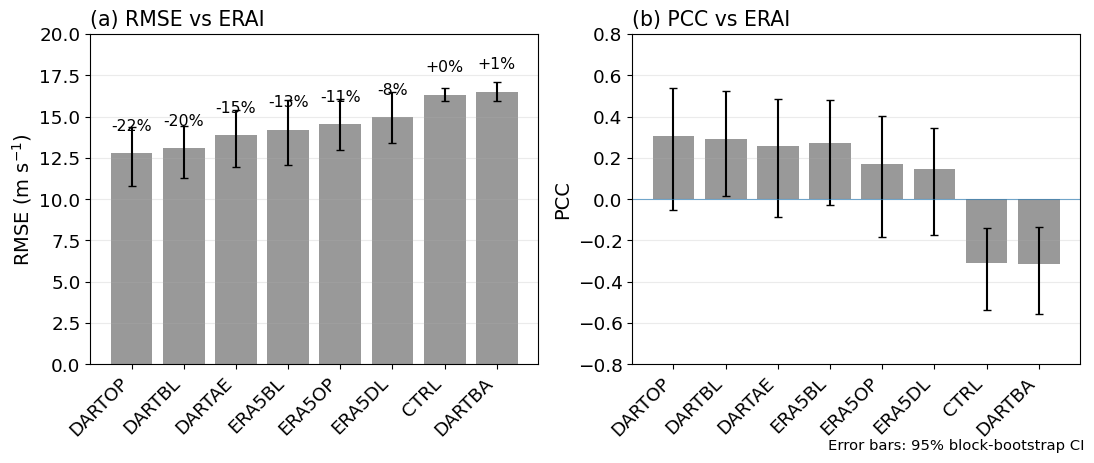

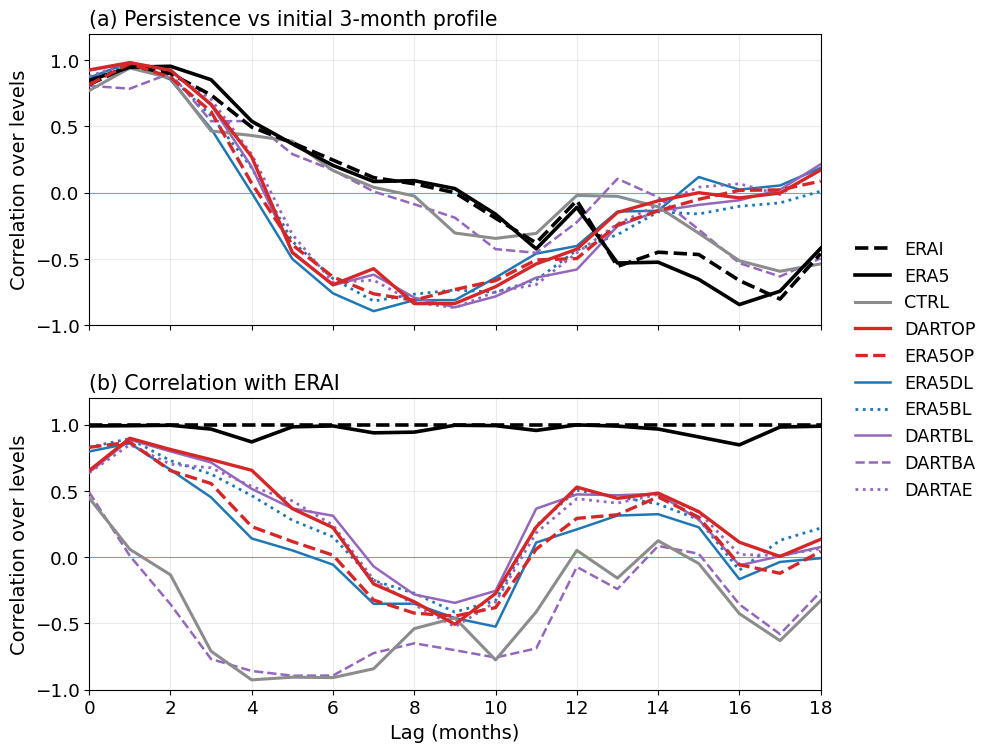

In [8]:
sources = [OTHER_REANALYSIS, *EXPERIMENTS]
save(plotter.plot_timepressure(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ua_sections_vs_{REFERENCE}.png")
save(plotter.plot_timepressure_diffs(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ua_diffs_vs_{REFERENCE}.png")
save(plotter.plot_amplitude(REFERENCE, sources, xlim=(0, 30), font_scale=FONT_SCALE), "qbo_ua_amplitude_rms.png")
for refs in (list(REFERENCES), [REFERENCE]):
    tag = "_".join(refs)
    fig, _ = plotter.plot_skill_bars(refs, EXPERIMENTS, table=skill[tag], font_scale=FONT_SCALE)
    save(fig, f"qbo_ua_skillbars_{tag}.png")
save(plotter.plot_lagcorr_persistence(REFERENCE, sources, font_scale=FONT_SCALE),
     f"qbo_ua_persistence_vs_{REFERENCE}.png")